# **Air Quality Index Prediction**
The Air Quality Index (AQI) Prediction Model uses machine learning algorithms to predict air quality levels based on pollutant concentrations, helping assess pollution and protect public health.

# Importing Required Libraries

We start by importing essential libraries for data manipulation, visualization, and model training.

In [71]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Loading and Exploring the Dataset

We load the dataset and perform initial exploration to understand its structure and characteristics.

In [72]:
file_path = "data.csv"

df = pd.read_csv(file_path, engine="python", on_bad_lines="skip")

print(df.head())
print(df.shape)

   stn_code       sampling_date           state   location agency  \
0     150.0  February - M021990  Andhra Pradesh  Hyderabad    NaN   
1     151.0  February - M021990  Andhra Pradesh  Hyderabad    NaN   
2     152.0  February - M021990  Andhra Pradesh  Hyderabad    NaN   
3     150.0     March - M031990  Andhra Pradesh  Hyderabad    NaN   
4     151.0     March - M031990  Andhra Pradesh  Hyderabad    NaN   

                                 type  so2   no2  rspm  spm  \
0  Residential, Rural and other Areas  4.8  17.4   NaN  NaN   
1                     Industrial Area  3.1   7.0   NaN  NaN   
2  Residential, Rural and other Areas  6.2  28.5   NaN  NaN   
3  Residential, Rural and other Areas  6.3  14.7   NaN  NaN   
4                     Industrial Area  4.7   7.5   NaN  NaN   

  location_monitoring_station  pm2_5        date  
0                         NaN    NaN  1990-02-01  
1                         NaN    NaN  1990-02-01  
2                         NaN    NaN  1990-02-01  
3 

In [73]:
df   #display dataset

,stn_code,sampling_date,state,location,agency,type,so2,no2,rspm,spm,location_monitoring_station,pm2_5,date
0,150.0,February - M021990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",4.8,17.4,NaN,NaN,NaN,NaN,1990-02-01
1,151.0,February - M021990,Andhra Pradesh,Hyderabad,NaN,Industrial Area,3.1,7.0,NaN,NaN,NaN,NaN,1990-02-01
2,152.0,February - M021990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",6.2,28.5,NaN,NaN,NaN,NaN,1990-02-01
3,150.0,March - M031990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",6.3,14.7,NaN,NaN,NaN,NaN,1990-03-01
4,151.0,March - M031990,Andhra Pradesh,Hyderabad,NaN,Industrial Area,4.7,7.5,NaN,NaN,NaN,NaN,1990-03-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...
80122,776.0,10-03-15,Goa,Ponda,Goa State Pollution Control Board,"Residential, Rural and other Areas",5.0,10.0,78.0,NaN,Ponda Town,28.0,2015-03-10
80123,776.0,12-03-15,Goa,Ponda,Goa State Pollution Control Board,"Residential, Rural and other Areas",4.0,9.0,78.0,NaN,Ponda Town,19.0,2015-03-12
80124,776.0,17-03-15,Goa,Ponda,Goa State Pollution Control Board,"Residential, Rural and other Areas",4.0,8.0,73.0,NaN,Ponda Town,24.0,2015-03-17
80125,776.0,19-03-15,Goa,Ponda,Goa State Pollution Control Board,"Residential, Rural and other Areas",4.0,9.0,43.0,NaN,Ponda Town,13.0,2015-03-19


In [74]:
df.info()    #display info about dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80127 entries, 0 to 80126
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   stn_code                     52376 non-null  float64
 1   sampling_date                80127 non-null  object 
 2   state                        80126 non-null  object 
 3   location                     80126 non-null  object 
 4   agency                       51133 non-null  object 
 5   type                         78932 non-null  object 
 6   so2                          72720 non-null  float64
 7   no2                          77122 non-null  float64
 8   rspm                         73566 non-null  float64
 9   spm                          38085 non-null  float64
 10  location_monitoring_station  75076 non-null  object 
 11  pm2_5                        1356 non-null   float64
 12  date                         80126 non-null  object 
dtypes: float64(6), o

# Data Preprocessing

This step involves handling missing values, encoding categorical features, and normalizing numerical features.

In [75]:
df.isnull().sum()   #check the total null values



,0
stn_code,27751
sampling_date,0
state,1
location,1
agency,28994
type,1195
so2,7407
no2,3005
rspm,6561
spm,42042


In [76]:
print(df.columns.tolist())

['stn_code', 'sampling_date', 'state', 'location', 'agency', 'type', 'so2', 'no2', 'rspm', 'spm', 'location_monitoring_station', 'pm2_5', 'date']


In [77]:
import pandas as pd
import numpy as np

# Step 1: Clean column names
df.columns = df.columns.str.strip()

# Step 2: Convert pollutant columns to numeric
pollutants = ['pm2_5', 'rspm', 'no2', 'so2']

for col in pollutants:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Step 3: Define CPCB concentration and AQI breakpoints
breakpoints = {
    'pm2_5': [
        (0, 30, 0, 50),
        (31, 60, 51, 100),
        (61, 90, 101, 200),
        (91, 120, 201, 300),
        (121, 250, 301, 400),
        (251, 500, 401, 500)
    ],
    'rspm': [
        (0, 50, 0, 50),
        (51, 100, 51, 100),
        (101, 250, 101, 200),
        (251, 350, 201, 300),
        (351, 430, 301, 400),
        (431, 1000, 401, 500)
    ],
    'no2': [
        (0, 40, 0, 50),
        (41, 80, 51, 100),
        (81, 180, 101, 200),
        (181, 280, 201, 300),
        (281, 400, 301, 400),
        (401, 1000, 401, 500)
    ],
    'so2': [
        (0, 40, 0, 50),
        (41, 80, 51, 100),
        (81, 380, 101, 200),
        (381, 800, 201, 300),
        (801, 1600, 301, 400),
        (1601, 2000, 401, 500)
    ]
}

# Step 4: Calculate an individual pollutant sub-index
def calculate_subindex(value, pollutant):

    if pd.isna(value) or value < 0:
        return np.nan

    for blo, bhi, ilo, ihi in breakpoints[pollutant]:

        if blo <= value <= bhi:

            return round(
                ((ihi - ilo) / (bhi - blo)) * (value - blo) + ilo
            )

    return np.nan


# Step 5: Calculate sub-indices for all available pollutants
for col in pollutants:

    df[col + '_subindex'] = df[col].apply(
        lambda x: calculate_subindex(x, col)
    )


# Step 6: Calculate the overall AQI
subindex_cols = [col + '_subindex' for col in pollutants]

# Require at least three pollutant measurements,
# including PM2.5 or the PM10 proxy (rspm).
valid_count = df[subindex_cols].notna().sum(axis=1)

has_particulate = (
    df['pm2_5_subindex'].notna() |
    df['rspm_subindex'].notna()
)

df['AQI'] = df[subindex_cols].max(axis=1)

df.loc[
    (valid_count < 3) | (~has_particulate),
    'AQI'
] = np.nan

# Step 7: Assign AQI categories
def aqi_category(aqi):

    if pd.isna(aqi):
        return 'Insufficient Data'
    elif aqi <= 50:
        return 'Good'
    elif aqi <= 100:
        return 'Satisfactory'
    elif aqi <= 200:
        return 'Moderate'
    elif aqi <= 300:
        return 'Poor'
    elif aqi <= 400:
        return 'Very Poor'
    else:
        return 'Severe'


df['AQI_Category'] = df['AQI'].apply(aqi_category)

# Step 8: Display results
print(df[['pm2_5', 'rspm', 'no2', 'so2', 'AQI', 'AQI_Category']].head())

print("\nAQI values calculated:", df['AQI'].notna().sum())
print("AQI values missing:", df['AQI'].isna().sum())

   pm2_5  rspm   no2  so2  AQI       AQI_Category
0    NaN   NaN  17.4  4.8  NaN  Insufficient Data
1    NaN   NaN   7.0  3.1  NaN  Insufficient Data
2    NaN   NaN  28.5  6.2  NaN  Insufficient Data
3    NaN   NaN  14.7  6.3  NaN  Insufficient Data
4    NaN   NaN   7.5  4.7  NaN  Insufficient Data

AQI values calculated: 66474
AQI values missing: 13653


In [78]:
df = df.dropna(subset=['AQI']).copy()

print("Dataset shape:", df.shape)
print(df[['AQI', 'AQI_Category']].head())

# Handling missing values
# Drop rows where AQI is missing, as it's our target variable

Dataset shape: (66474, 19)
        AQI  AQI_Category
1036  129.0      Moderate
1037  117.0      Moderate
1038   88.0  Satisfactory
1039   83.0  Satisfactory
1040  130.0      Moderate


In [79]:
df.to_csv('aqi_calculated.csv', index=False)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


# Exploratory Data Analysis (EDA)

We visualize the data to identify patterns, correlations, and important features.

In [80]:
df.fillna(df.select_dtypes(include=['number']).mean(), inplace=True)

In [81]:
# Columns to remove
drop_columns = ['location', 'date', 'AQI_Category']

# Drop only columns that exist
df = df.drop(columns=drop_columns, errors='ignore')

print("Remaining columns:", df.columns.tolist())
print(df.head())

Remaining columns: ['stn_code', 'sampling_date', 'state', 'agency', 'type', 'so2', 'no2', 'rspm', 'spm', 'location_monitoring_station', 'pm2_5', 'pm2_5_subindex', 'rspm_subindex', 'no2_subindex', 'so2_subindex', 'AQI']
      stn_code sampling_date           state  \
1036      95.0      1/2/2004  Andhra Pradesh   
1037      95.0      1/5/2004  Andhra Pradesh   
1038      95.0      1/9/2004  Andhra Pradesh   
1039      95.0     1/12/2004  Andhra Pradesh   
1040      95.0      16-01-04  Andhra Pradesh   

                                            agency             type   so2  \
1036  Andhra Pradesh State Pollution Control Board  Industrial Area  12.9   
1037  Andhra Pradesh State Pollution Control Board  Industrial Area  10.4   
1038  Andhra Pradesh State Pollution Control Board  Industrial Area   7.6   
1039  Andhra Pradesh State Pollution Control Board  Industrial Area   7.3   
1040  Andhra Pradesh State Pollution Control Board  Industrial Area   6.8   

        no2   rspm    spm    

In [82]:

# Define target (dependent variable) and features (independent variables)
target = 'AQI'
features = [col for col in df.columns if col != target]  # All columns except AQI

X = df[features]  # Features dataset
y = df[target]  # Target variable

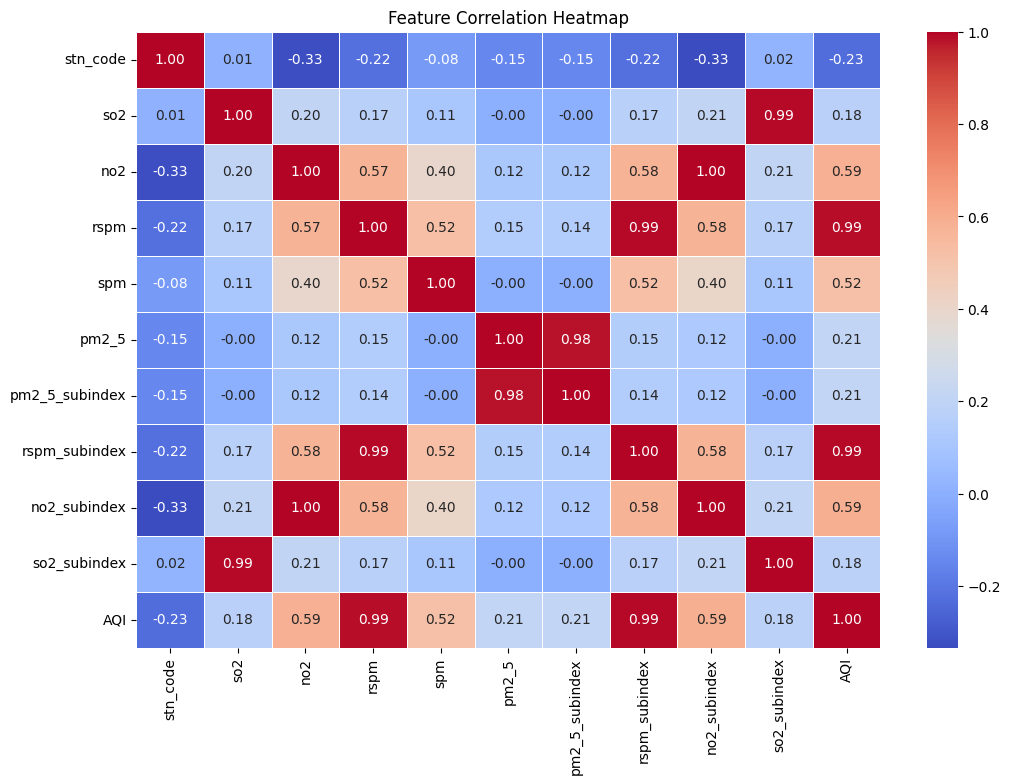

In [83]:
num_df = df.select_dtypes(include=['number'])  # Keep only numeric columns

# Compute correlation matrix
corr_matrix = num_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()


# Splitting Data into Training and Testing Sets

We divide the dataset into training and test sets to evaluate model performance.


In [84]:
# Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [85]:
from sklearn.model_selection import train_test_split

# Remove date and other non-numeric columns
X = df.drop(columns=['AQI', 'date', 'sampling_date',
                     'state', 'location', 'agency',
                     'type', 'location_monitoring_station',
                     'AQI_Category'], errors='ignore')

# Target variable
y = df['AQI']

# Keep only numeric features
X = X.select_dtypes(include=['number'])

# Handle missing values
X = X.replace([float('inf'), float('-inf')], float('nan'))
X = X.fillna(X.median())

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (53179, 10)
Testing data: (13295, 10)


In [86]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Feature scaling completed successfully!
Training shape: (53179, 10)
Testing shape: (13295, 10)


# Choosing, Training and Evaluating the Models

We train multiple machine learning models and compare their performance.

In [87]:
#initialization of model to test
models = {
    "Linear Regression": LinearRegression(),  # Simple baseline model
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),  # Handles non-linearity well
    "XGBoost": XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42)  # Gradient boosting for performance
}


In [88]:
# Train and Evaluate Models
results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)  # Train the model on scaled data
    y_pred = model.predict(X_test_scaled)  # Predict on test set
    # Evaluate model performance
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    results[name] = {'MAE': mae, 'RMSE': rmse, 'R2 Score': r2}  # Store results
    print(f"{name} Performance:\nMAE: {mae:.2f}, RMSE: {rmse:.2f}, R2 Score: {r2:.2f}\n")

Linear Regression Performance:
MAE: 1.35, RMSE: 4.75, R2 Score: 0.99

Random Forest Performance:
MAE: 0.11, RMSE: 2.72, R2 Score: 1.00

XGBoost Performance:
MAE: 0.44, RMSE: 2.86, R2 Score: 1.00



In [89]:
# Convert results to DataFrame for better visualization
results_df = pd.DataFrame(results).T
print(results_df)

                        MAE      RMSE  R2 Score
Linear Regression  1.352446  4.745277  0.992780
Random Forest      0.112406  2.715112  0.997636
XGBoost            0.443855  2.856307  0.997384


# Model Performance Comparison

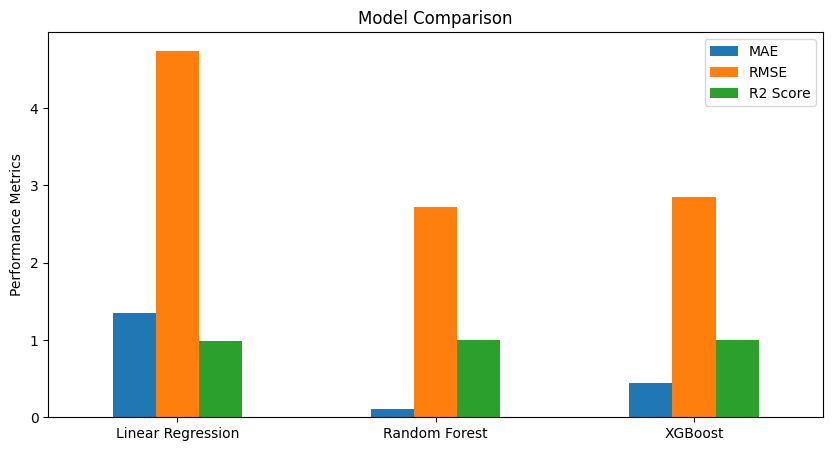

In [90]:

import matplotlib.pyplot as plt

# Plot model performance
results_df.plot(kind='bar', figsize=(10, 5))
plt.title("Model Comparison")
plt.ylabel("Performance Metrics")
plt.xticks(rotation=0)
plt.show()

# Feature Importance Analysis

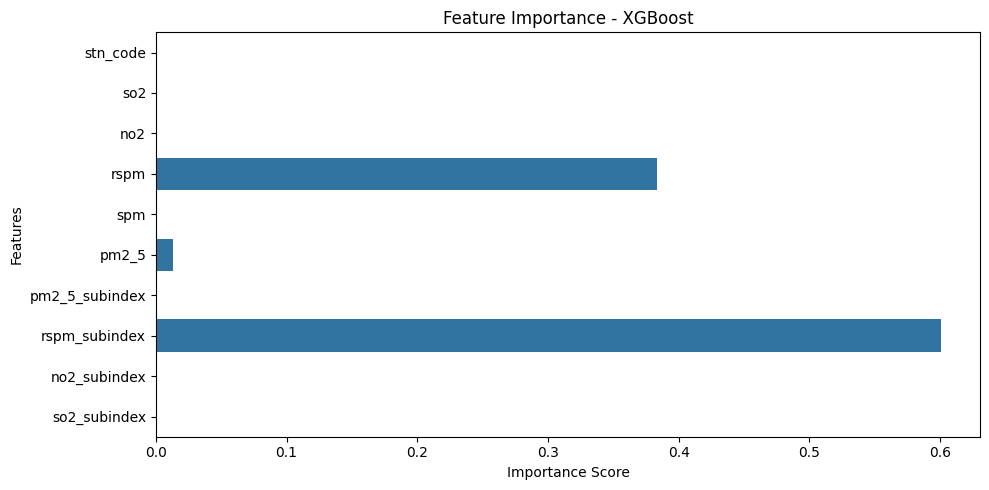

In [91]:
# Import required libraries
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBRegressor

# Define and train the XGBoost model
models["XGBoost"] = XGBRegressor(
    n_estimators=100,
    random_state=42
)

models["XGBoost"].fit(X_train_scaled, y_train)

# Get feature importance
feature_importance = models["XGBoost"].feature_importances_

# Get feature names
features = X.columns

# Create feature importance plot
plt.figure(figsize=(10, 5))

sns.barplot(
    x=feature_importance,
    y=features
)

plt.title("Feature Importance - XGBoost")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

# Hyperparameter Tuning

In [92]:
# Hyperparameter Tuning for XGBoost
# Define parameter grid for tuning
tuning_params = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

In [ ]:
# Perform grid search with cross-validation
grid_search = GridSearchCV(XGBRegressor(objective='reg:squarederror'), tuning_params, cv=5, scoring='r2')
grid_search.fit(X_train_scaled, y_train)
print(f"Best XGBoost Parameters: {grid_search.best_params_}")


# Saving the best model

In [ ]:
import joblib
joblib.dump(models["XGBoost"], "best_aqi_model.pkl")

# Downloading the Saved Model

In [ ]:
from google.colab import files
files.download("best_aqi_model.pkl")

# Optimized Model Training and Evaluation

In [ ]:
# Train the best XGBoost model with optimized parameters
best_xgb = XGBRegressor(objective='reg:squarederror',
                        learning_rate=0.2,
                        max_depth=5,
                        n_estimators=100,
                        random_state=42)

best_xgb.fit(X_train_scaled, y_train)
y_pred_xgb = best_xgb.predict(X_test_scaled)

# Evaluate the optimized model
mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2 = r2_score(y_test, y_pred_xgb)

print(f"Optimized XGBoost Performance:\nMAE: {mae:.2f}, RMSE: {rmse:.2f}, R2 Score: {r2:.2f}")

# Save the optimized model
import joblib
joblib.dump(best_xgb, "optimized_xgb_model.pkl")

# Making Predictions with the Trained Model

In [ ]:

new_data = X_test_scaled[:5]  # Use the first 5 test samples as an example
predictions = best_xgb.predict(new_data)
print("Predicted AQI values:", predictions)

# Saving Predictions to a File

In [ ]:

pred_df = pd.DataFrame({'Predicted_AQI': predictions})
pred_df.to_csv("aqi_predictions.csv", index=False)
print("Predictions saved to aqi_predictions.csv")


# Actual vs. Predicted AQI Visualization

In [ ]:

plt.figure(figsize=(8, 5))
plt.plot(y_test[:5].values, label="Actual AQI", marker='o')
plt.plot(predictions, label="Predicted AQI", marker='s')
plt.xlabel("Sample Index")
plt.ylabel("AQI Value")
plt.title("Actual vs. Predicted AQI")
plt.legend()
plt.show()